# Phase I — How SASRec changes MovieLens histories into recommendations

**AI-assisted pair | Cosmic Mirage**

## Research question

**How does SASRec change the genre and popularity profile of a user's recent interaction history when it produces a Top-20 list, and how sensitive are those recommendations to the arbitrary order of same-second events?**

The main analysis compares each user's latest 20 training interactions with their full-catalog Top-20 recommendations. We use the unseen catalog and a training-popularity Top-20 as reference lists. A separate controlled sensitivity analysis reverses only events sharing an identical timestamp inside the model-visible history, while preserving the same items and candidate set.

This is a Phase I black-box analysis: recommendations and scores are observed, but learned weights and attention are not inspected. Model internals are reserved for Phase II.

## Shared model and sequence protocol

This notebook loads the checkpoint and its architecture settings from this repository. It uses the matching upstream SASRec implementation, processed `ml-1m.txt`, and SASRec-to-MovieLens ID maps. It does not retrain the model. Raw MovieLens ratings are used to verify the mapping, chronology, metadata joins, and tie counts.

The sequence order stored by SASRec is the primary order. MovieLens records rating timestamps only to the second; tied events do not have a known order. The tie-reversal analysis is a **sensitivity stress test**, not an alternate claim about true chronology. The final held-out item is also affected by the inherited event order, so test hit rates are diagnostic only.

## Planned outputs

1. Per-user genre-share changes with user-level bootstrap intervals.
2. Recommendation exposure by item-popularity quintile versus unseen-catalog and popularity references.
3. Top-20 rank and genre changes when same-second events are reversed in the input sequence.
4. A sampled-negative next-item hit-rate sanity check, clearly separated from the behavior findings.


In [1]:
from pathlib import Path
from argparse import Namespace
from collections import Counter
import hashlib
import json
import os
import re
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Find the repository even if Jupyter starts in this notebook's directory.
_search = [Path.cwd().resolve()] + list(Path.cwd().resolve().parents)
REPO_ROOT = next((p for p in _search if (p / "artifacts/checkpoints/SASREC_CHECKPOINT.pth").is_file()), None)
if REPO_ROOT is None:
    REPO_ROOT = next((p / "SasRec-Vis-Analysis" for p in _search
                      if (p / "SasRec-Vis-Analysis/artifacts/checkpoints/SASREC_CHECKPOINT.pth").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from the AIViz workspace or the SasRec-Vis-Analysis repository.")

UPSTREAM_PY = REPO_ROOT / "src/model/SASRec.pytorch/python"
DATA_FILE = UPSTREAM_PY / "data/ml-1m.txt"
CHECKPOINT = REPO_ROOT / "artifacts/checkpoints/SASREC_CHECKPOINT.pth"
ARGS_FILE = REPO_ROOT / "artifacts/checkpoints/args.txt"
RAW_DIR = REPO_ROOT / "src/data/raw/ml-1m"
MAP_DIR = REPO_ROOT / "src/data/mapping-source"
OUT_DIR = REPO_ROOT / "research/phase1/ai_pair/outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_FILE.is_file():
    raise FileNotFoundError("Install the repository's upstream model submodule (npm run setup:model) to obtain ml-1m.txt.")
sys.path.insert(0, str(UPSTREAM_PY))
from model import SASRec

torch.set_num_threads(min(2, os.cpu_count() or 1))
np.random.seed(42)
TOP_K = 20
MAXLEN = 200
N_NEGATIVES = 100
BOOTSTRAP_DRAWS = 1000

print("Repository:", REPO_ROOT)
print("Checkpoint:", CHECKPOINT.name)
print("Checkpoint SHA-256:", hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest())
print("Upstream model source:", UPSTREAM_PY)
print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__, "| CPU inference")


/Users/tim/Library/Python/3.7/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /Users/tim/Desktop/JKU/Master AI/AIViz/SasRec-Vis-Analysis
Checkpoint: SASREC_CHECKPOINT.pth
Checkpoint SHA-256: 5e3af2278df2092c09f02b3f817469f834e93450ed6c14abe35e75ce9a60d1ed
Upstream model source: /Users/tim/Desktop/JKU/Master AI/AIViz/SasRec-Vis-Analysis/src/model/SASRec.pytorch/python
Python: 3.7.2 | PyTorch: 1.13.1 | CPU inference


## 1. Reconstruct and audit the shared interaction sequence

MovieLens `ratings.dat` is the raw event source. We apply the SASRec one-pass 5-core filter (retain events from users and movies with at least five raw ratings), translate IDs through the repository maps, and compare every user's timestamp-sorted raw sequence with the processed sequence used by the checkpoint. Stable original file row order breaks timestamp ties for this audit.

In [2]:
ratings = pd.read_csv(
    RAW_DIR / "ratings.dat", sep="::", engine="python", header=None,
    names=["original_user_id", "original_movie_id", "rating", "timestamp"],
    dtype={"original_user_id": "int32", "original_movie_id": "int32", "rating": "int32", "timestamp": "int32"},
)
ratings["source_row"] = np.arange(len(ratings), dtype=np.int64)
raw_user_counts = ratings.original_user_id.value_counts()
raw_item_counts = ratings.original_movie_id.value_counts()
filtered = ratings[
    ratings.original_user_id.map(raw_user_counts).ge(5)
    & ratings.original_movie_id.map(raw_item_counts).ge(5)
].copy()

user_map = pd.read_csv(MAP_DIR / "sas_to_original_users.txt", sep=r"\s+", header=None,
                       names=["sas_user_id", "original_user_id"], dtype="int32")
item_map = pd.read_csv(MAP_DIR / "sas_to_original_items.txt", sep=r"\s+", header=None,
                       names=["sas_item_id", "original_movie_id"], dtype="int32")
filtered = filtered.merge(user_map, on="original_user_id", validate="many_to_one")
filtered = filtered.merge(item_map, on="original_movie_id", validate="many_to_one")
filtered = filtered.sort_values(["sas_user_id", "timestamp", "source_row"], kind="mergesort")

# Read the exact row order used by the checkpoint's upstream training pipeline.
processed = np.loadtxt(DATA_FILE, dtype=np.int32)
upstream_sequences = {}
for sas_user, sas_item in processed:
    upstream_sequences.setdefault(int(sas_user), []).append(int(sas_item))
raw_sorted_sequences = {}
raw_sorted_rows = {}
for sas_user, group in filtered.groupby("sas_user_id", sort=True):
    raw_sorted_sequences[int(sas_user)] = group.sas_item_id.astype(int).tolist()
    raw_sorted_rows[int(sas_user)] = group.reset_index(drop=True)

assert len(filtered) == len(processed) == 999611
assert len(upstream_sequences) == len(user_map) == 6040
assert len(item_map) == 3416
sequence_match_count = sum(raw_sorted_sequences[u] == upstream_sequences[u] for u in upstream_sequences)
assert sequence_match_count == len(upstream_sequences), "Raw timestamp/file-row order does not match the shared processed sequence."
assert not filtered.duplicated(["original_user_id", "original_movie_id"]).any()

user_sequences = upstream_sequences
n_users = len(user_map)
n_items = len(item_map)

time_group_sizes = filtered.groupby(["sas_user_id", "timestamp"]).size()
tied_time_groups = time_group_sizes[time_group_sizes > 1]
latest_timestamps = filtered.groupby("sas_user_id").timestamp.max()
latest_rows = filtered.merge(latest_timestamps.rename("latest_timestamp"), on="sas_user_id")
latest_rows = latest_rows[latest_rows.timestamp == latest_rows.latest_timestamp]
latest_tie_sizes = latest_rows.groupby("sas_user_id").size().to_dict()

print("Raw ratings:", len(ratings))
print("5-core filtered events/users/movies:", len(filtered), n_users, n_items)
print("Exact per-user sequence matches with shared processed file:", sequence_match_count, "/", n_users)
print("User-timestamp groups with ties:", len(tied_time_groups), "of", len(time_group_sizes))
print("Events in tied timestamp groups:", int(tied_time_groups.sum()))
print("Users with tied latest timestamp:", sum(size > 1 for size in latest_tie_sizes.values()), "/", n_users)
print("Largest latest-timestamp group:", max(latest_tie_sizes.values()))


Raw ratings: 1000209
5-core filtered events/users/movies: 999611 6040 3416
Exact per-user sequence matches with shared processed file: 6040 / 6040
User-timestamp groups with ties: 244895 of 470957
Events in tied timestamp groups: 773549
Users with tied latest timestamp: 2544 / 6040
Largest latest-timestamp group: 18


## 2. Define histories, targets, metadata, and the tie perturbation

The app's behavior analyses use training-only histories: all but the final two events are training history, with the previous event reserved for validation and the final event reserved for test. Recommendations use the training history, truncated to the model's 200-event context. For the tie sensitivity check, we reverse items only within equal-timestamp groups inside that visible context. Subgrouping by the latest visible timestamp group uses the training prefix and excludes validation and test events. The input item set and eligible recommendation catalog stay fixed.

In [3]:
train_by_user, valid_by_user, test_by_user, test_context_by_user = {}, {}, {}, {}
visible_train_by_user, reversed_visible_by_user = {}, {}
tie_groups_visible, tied_events_visible = {}, {}
visible_latest_tie_size, target_tie_size = {}, {}

for user_id in sorted(user_sequences):
    seq = user_sequences[user_id]
    rows = raw_sorted_rows[user_id]
    times = rows.timestamp.astype(int).tolist()
    if len(seq) >= 4:
        train_by_user[user_id] = seq[:-2]
        valid_by_user[user_id] = seq[-2]
        test_by_user[user_id] = seq[-1]
        test_context_by_user[user_id] = seq[:-1]
    else:
        train_by_user[user_id] = seq
        valid_by_user[user_id] = None
        test_by_user[user_id] = None
        test_context_by_user[user_id] = seq

    train_times = times[:-2] if len(seq) >= 4 else times
    visible_items = train_by_user[user_id][-MAXLEN:]
    visible_times = train_times[-MAXLEN:]
    visible_train_by_user[user_id] = visible_items

    # Reverse only contiguous blocks with identical timestamps in the model-visible tail.
    perturbed = list(visible_items)
    start = 0
    user_tie_groups = 0
    user_tied_events = 0
    while start < len(visible_times):
        end = start + 1
        while end < len(visible_times) and visible_times[end] == visible_times[start]:
            end += 1
        if end - start > 1:
            perturbed[start:end] = reversed(perturbed[start:end])
            user_tie_groups += 1
            user_tied_events += end - start
        start = end
    latest_block_size = 0
    if visible_times:
        latest_block_size = 1
        while latest_block_size < len(visible_times) and visible_times[-latest_block_size - 1] == visible_times[-1]:
            latest_block_size += 1
    visible_latest_tie_size[user_id] = latest_block_size
    reversed_visible_by_user[user_id] = perturbed
    tie_groups_visible[user_id] = user_tie_groups
    tied_events_visible[user_id] = user_tied_events
    target_tie_size[user_id] = int(latest_tie_sizes.get(user_id, 1))

eligible_users = [u for u in sorted(user_sequences) if test_by_user[u] is not None]
print("Eligible users with one validation and one test event:", len(eligible_users))
print("Users with at least one same-second group in the model-visible training history:",
      sum(tie_groups_visible[u] > 0 for u in eligible_users))
print("Tie perturbation changes no input item set:", all(
    set(visible_train_by_user[u]) == set(reversed_visible_by_user[u]) for u in eligible_users
))

movies = pd.read_csv(RAW_DIR / "movies.dat", sep="::", engine="python", header=None,
                     names=["original_movie_id", "title", "genres"], encoding="latin-1")
users = pd.read_csv(RAW_DIR / "users.dat", sep="::", engine="python", header=None,
                    names=["original_user_id", "gender", "age", "occupation", "zip_code"],
                    dtype={"original_user_id": "int32", "age": "int32", "occupation": "int32", "zip_code": str})
item_metadata = item_map.merge(movies, on="original_movie_id", validate="one_to_one")
item_metadata["release_year"] = pd.to_numeric(item_metadata.title.str.extract(r"\((\d{4})\)\s*$")[0], errors="coerce")
item_metadata["genre_list"] = item_metadata.genres.astype(str).str.split("|")
user_metadata = user_map.merge(users, on="original_user_id", validate="one_to_one").set_index("sas_user_id")

all_genres = sorted({g for group in item_metadata.genre_list for g in group})
genre_to_index = {genre: i for i, genre in enumerate(all_genres)}
genre_matrix = np.zeros((n_items, len(all_genres)), dtype=np.float32)
for row in item_metadata.itertuples():
    labels = list(dict.fromkeys(row.genre_list))
    for label in labels:
        genre_matrix[int(row.sas_item_id) - 1, genre_to_index[label]] = 1.0 / len(labels)
assert np.allclose(genre_matrix.sum(axis=1), 1.0)
item_metadata_by_id = item_metadata.set_index("sas_item_id").to_dict("index")
release_year_by_item = item_metadata.set_index("sas_item_id").release_year.to_dict()


Eligible users with one validation and one test event: 6040
Users with at least one same-second group in the model-visible training history: 6037
Tie perturbation changes no input item set: True


## 3. Load the shared checkpoint without retraining

The model implementation, checkpoint, and architecture settings are all from the shared repository. Only the inference device is set to CPU for this notebook. The item IDs passed to the model are the repository's SASRec IDs.

In [4]:
checkpoint_args = {}
for line in ARGS_FILE.read_text().splitlines():
    if "," in line:
        key, value = line.split(",", 1)
        checkpoint_args[key] = value.strip()

model_config = {
    "maxlen": int(checkpoint_args.get("maxlen", 200)),
    "hidden_units": int(checkpoint_args.get("hidden_units", 50)),
    "num_blocks": int(checkpoint_args.get("num_blocks", 2)),
    "num_heads": int(checkpoint_args.get("num_heads", 1)),
    "dropout_rate": float(checkpoint_args.get("dropout_rate", 0.2)),
    "norm_first": checkpoint_args.get("norm_first", "False").lower() in ("true", "1"),
    "device": "cpu",
}
MAXLEN = model_config["maxlen"]
assert MAXLEN == 200

model = SASRec(n_users, n_items, Namespace(**model_config))
state_dict = torch.load(str(CHECKPOINT), map_location="cpu")
model.load_state_dict(state_dict, strict=True)
model.eval()
checkpoint_sha256 = hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest()
print("Loaded checkpoint SHA-256:", checkpoint_sha256)
print("Loaded architecture:", model_config)


Loaded checkpoint SHA-256: 5e3af2278df2092c09f02b3f817469f834e93450ed6c14abe35e75ce9a60d1ed
Loaded architecture: {'maxlen': 200, 'hidden_units': 50, 'num_blocks': 2, 'num_heads': 1, 'dropout_rate': 0.2, 'norm_first': False, 'device': 'cpu'}


## 4. Generate full-catalog recommendations for all eligible users

For each user, score every movie, exclude items in the training history, and retain the Top-20. We run the same checkpoint on the canonical and tie-reversed contexts. We also score the canonical test context (training plus validation event) for a separate sampled-negative sanity check.

In [5]:
def left_pad(histories, maxlen):
    batch = np.zeros((len(histories), maxlen), dtype=np.int32)
    for i, history in enumerate(histories):
        visible = list(history)[-maxlen:]
        if visible:
            batch[i, -len(visible):] = visible
    return batch


def score_histories(model, user_ids, histories, item_ids, batch_size=64):
    outputs = []
    for start in range(0, len(histories), batch_size):
        end = min(start + batch_size, len(histories))
        seq_batch = left_pad(histories[start:end], MAXLEN)
        with torch.no_grad():
            logits = model.predict(
                np.asarray(user_ids[start:end], dtype=np.int64),
                seq_batch,
                np.asarray(item_ids, dtype=np.int32),
            )
        outputs.append(logits.detach().cpu().numpy().astype(np.float32))
    return np.concatenate(outputs, axis=0)

candidate_ids = np.arange(1, n_items + 1, dtype=np.int32)
canonical_histories = [train_by_user[u] for u in eligible_users]
reversed_histories = [reversed_visible_by_user[u] for u in eligible_users]
test_histories = [test_context_by_user[u] for u in eligible_users]
inference_histories = canonical_histories + reversed_histories + test_histories
inference_users = eligible_users * 3

start_time = time.time()
all_scores = score_histories(model, inference_users, inference_histories, candidate_ids)
num_eval_users = len(eligible_users)
canonical_scores = all_scores[:num_eval_users]
reversed_scores = all_scores[num_eval_users:2 * num_eval_users]
test_scores = all_scores[2 * num_eval_users:]
del all_scores
print("Scored canonical, tie-reversed, and test contexts for", num_eval_users, "users in",
      round(time.time() - start_time, 1), "seconds")

train_popularity = np.bincount(
    np.asarray([item for u in eligible_users for item in train_by_user[u]], dtype=np.int32),
    minlength=n_items + 1,
)[1:]


def topk_excluding_seen(score_matrix, histories, k):
    result = np.empty((len(histories), k), dtype=np.int32)
    for row, history in enumerate(histories):
        scores = score_matrix[row].copy()
        if history:
            scores[np.asarray(sorted(set(history)), dtype=np.int32) - 1] = -np.inf
        order = np.argsort(-scores, kind="mergesort")[:k]
        result[row] = order + 1
    return result

canonical_topk = topk_excluding_seen(canonical_scores, canonical_histories, TOP_K)
reversed_topk = topk_excluding_seen(reversed_scores, canonical_histories, TOP_K)
print("Recommendation matrix:", canonical_topk.shape, "| all lists exclude training-seen movies")


Scored canonical, tie-reversed, and test contexts for 6040 users in 39.8 seconds


Recommendation matrix: (6040, 20) | all lists exclude training-seen movies


## 5. Compare genre profiles, popularity exposure, and next-item hits

Genre shares allocate each movie's mass equally over its genres. Popularity profiles compare each user's latest up to 20 training interactions (input), unseen catalog, and full-catalog Top-20 recommendations (output) across item-popularity quintiles. Popularity ranks are computed from training-prefix interaction counts. A user contributes one profile, regardless of history length. Confidence intervals resample users, not individual movies. The sampled-negative hit rate is reported only as a model/evaluation sanity check; the behavior analysis uses full-catalog recommendation lists.

In [6]:
def genre_profile(item_ids):
    if not item_ids:
        return np.zeros(len(all_genres), dtype=np.float64)
    return genre_matrix[np.asarray(item_ids, dtype=np.int32) - 1].mean(axis=0).astype(np.float64)

# Equal-sized popularity-rank quintiles, computed from the training prefix only.
popularity_order = np.lexsort((candidate_ids, -train_popularity))
popularity_quintile = np.empty(n_items, dtype=np.int32)
for rank, item_index in enumerate(popularity_order):
    popularity_quintile[item_index] = 4 - min(4, (rank * 5) // n_items)
popularity_labels = ["Q1 rare", "Q2", "Q3", "Q4", "Q5 popular"]

per_user_rows = []
profile_rows = []
popularity_profile_rows = []

# Fast vector lookups keep the per-user catalog reference tractable.
release_year_array = item_metadata.set_index("sas_item_id").release_year.reindex(range(1, n_items + 1)).to_numpy(dtype=float)
popularity_order_ids = candidate_ids[np.lexsort((candidate_ids, -train_popularity))]
release_rows = []
recommendation_records = []
for row, user_id in enumerate(eligible_users):
    history = train_by_user[user_id]
    recent = history[-20:]
    rec_ids = canonical_topk[row].tolist()
    alt_ids = reversed_topk[row].tolist()
    seen = set(history)
    unseen_mask = np.ones(n_items, dtype=bool)
    if seen:
        unseen_mask[np.asarray(sorted(seen), dtype=np.int32) - 1] = False
    unseen = (np.flatnonzero(unseen_mask) + 1).astype(np.int32).tolist()
    popular_ids = [int(item) for item in popularity_order_ids if int(item) not in seen][:TOP_K]

    history_q = np.bincount(
        popularity_quintile[np.asarray(recent, dtype=np.int32) - 1], minlength=5
    ) / float(len(recent))
    hp = genre_profile(recent)
    rp = genre_profile(rec_ids)
    cp = genre_profile(unseen)
    pp = genre_profile(popular_ids)
    demo = user_metadata.loc[user_id]
    tie_count = int(tie_groups_visible[user_id])

    for g, genre in enumerate(all_genres):
        profile_rows.append({
            "user_id": user_id, "genre": genre, "gender": demo.gender, "age": int(demo.age),
            "history_share": hp[g], "recommendation_share": rp[g],
            "delta_recommendation_minus_history": rp[g] - hp[g],
            "unseen_catalog_share": cp[g], "popularity_top20_share": pp[g],
            "visible_tie_groups": tie_count,
        })

    # User-level availability and exposure in item-popularity quintiles.
    unseen_arr = np.asarray(unseen, dtype=np.int32)
    catalog_q = np.bincount(popularity_quintile[unseen_arr - 1], minlength=5) / float(len(unseen_arr))
    rec_q = np.bincount(popularity_quintile[np.asarray(rec_ids) - 1], minlength=5) / float(TOP_K)
    pop_q = np.bincount(popularity_quintile[np.asarray(popular_ids) - 1], minlength=5) / float(TOP_K)
    for q in range(5):
        popularity_profile_rows.append({
            "user_id": user_id, "popularity_quintile": popularity_labels[q],
            "latest20_history_share": history_q[q],
            "unseen_catalog_share": catalog_q[q], "recommendation_exposure_share": rec_q[q],
            "popularity_reference_share": pop_q[q],
        })

    def mean_known_year(items):
        values = release_year_array[np.asarray(items, dtype=np.int32) - 1]
        values = values[np.isfinite(values)]
        return (float(values.mean()), int(len(values))) if len(values) else (np.nan, 0)
    history_year, history_year_n = mean_known_year(recent)
    recommendation_year, recommendation_year_n = mean_known_year(rec_ids)
    catalog_year, catalog_year_n = mean_known_year(unseen)
    popular_year, popular_year_n = mean_known_year(popular_ids)
    release_rows.append({
        "user_id": user_id, "history_mean_year": history_year,
        "recommendation_mean_year": recommendation_year, "unseen_catalog_mean_year": catalog_year,
        "popularity_top20_mean_year": popular_year, "history_known_years": history_year_n,
        "recommendation_known_years": recommendation_year_n,
        "catalog_known_years": catalog_year_n, "popularity_reference_known_years": popular_year_n,
    })

    for rank, item in enumerate(rec_ids, 1):
        meta = item_metadata_by_id[item]
        recommendation_records.append({
            "user_id": user_id, "rank": rank, "sas_item_id": item,
            "original_movie_id": int(meta["original_movie_id"]), "title": str(meta["title"]),
            "genres": str(meta["genres"]), "release_year": meta["release_year"],
            "training_popularity": int(train_popularity[item - 1]),
            "popularity_quintile": popularity_labels[int(popularity_quintile[item - 1])],
        })

    # Per-user information used for grouping and uncertainty estimates.
    per_user_rows.append({
        "user_id": user_id, "gender": str(demo.gender), "age": int(demo.age),
        "occupation": int(demo.occupation), "train_history_length": len(history),
        "visible_tie_groups": tie_count, "visible_tied_events": int(tied_events_visible[user_id]),
        "visible_latest_timestamp_tie_size": int(visible_latest_tie_size[user_id]),
        "full_sequence_latest_timestamp_tie_size": int(target_tie_size[user_id]),
        "recommendation_mean_training_popularity": float(np.mean(train_popularity[np.asarray(rec_ids) - 1])),
    })

profiles = pd.DataFrame(profile_rows)
popularity_profiles = pd.DataFrame(popularity_profile_rows)
release_summary_users = pd.DataFrame(release_rows)
user_summary = pd.DataFrame(per_user_rows)
top20_table = pd.DataFrame(recommendation_records)

# User-level percentile bootstrap for each genre's mean recommendation-history change.
def bootstrap_mean_ci(values, seed, draws=BOOTSTRAP_DRAWS):
    vals = np.asarray(values, dtype=float)
    vals = vals[np.isfinite(vals)]
    if len(vals) == 0:
        return (np.nan, np.nan)
    rng = np.random.RandomState(seed)
    means = np.empty(draws, dtype=float)
    for i in range(draws):
        means[i] = vals[rng.randint(0, len(vals), len(vals))].mean()
    return tuple(np.quantile(means, [0.025, 0.975]))

genre_summary_rows = []
for index, genre in enumerate(all_genres):
    block = profiles[profiles.genre == genre]
    delta = block.delta_recommendation_minus_history.to_numpy()
    low, high = bootstrap_mean_ci(delta, 1000 + index)
    genre_summary_rows.append({
        "genre": genre, "users": len(block), "history_share_mean": block.history_share.mean(),
        "recommendation_share_mean": block.recommendation_share.mean(),
        "delta_mean": delta.mean(), "delta_ci_low": low, "delta_ci_high": high,
        "unseen_catalog_share_mean": block.unseen_catalog_share.mean(),
        "popularity_top20_share_mean": block.popularity_top20_share.mean(),
    })
genre_summary = pd.DataFrame(genre_summary_rows).sort_values("delta_mean", ascending=True)

# Sampled-negative test hit rate: protocol sanity check, not the main behavior outcome.
test_rows = []
for row, user_id in enumerate(eligible_users):
    target = int(test_by_user[user_id])
    full_sequence = set(user_sequences[user_id])
    eligible_negatives = np.asarray([item for item in candidate_ids if int(item) not in full_sequence], dtype=np.int32)
    rng = np.random.RandomState(42 + int(user_id))
    negatives = rng.choice(eligible_negatives, size=N_NEGATIVES, replace=False)
    candidates = np.concatenate(([target], negatives))
    scores = test_scores[row, candidates - 1]
    rank = int(np.sum(scores[1:] > scores[0])) + 1
    target_q = popularity_labels[int(popularity_quintile[target - 1])]
    test_rows.append({
        "user_id": user_id, "target_item": target, "target_popularity_quintile": target_q,
        "rank_among_101": rank, "hit_at_10": int(rank <= 10),
        "target_latest_timestamp_tie_size": int(target_tie_size[user_id]),
    })
test_results = pd.DataFrame(test_rows)
print("Behavior profiles computed for", len(eligible_users), "users and", len(all_genres), "genres")
print("Sampled-negative sanity check: Hit@10 = %.4f | NDCG@10 = %.4f" % (
    test_results.hit_at_10.mean(),
    np.mean([1.0 / np.log2(row + 1) if row <= 10 else 0.0 for row in test_results.rank_among_101]),
))


Behavior profiles computed for 6040 users and 18 genres
Sampled-negative sanity check: Hit@10 = 0.8262 | NDCG@10 = 0.5973


## 6. Same-second ordering sensitivity

For each user, the canonical and perturbed inputs contain the same model-visible movies and use the same candidate set. Only the order within equal-timestamp groups changes. We compare Top-20 overlap, rank-sensitive overlap, and genre-profile distance. This measures sensitivity to an arbitrary ordering choice; it does not establish which sequence is historically correct.

In [7]:
def rbo_dissimilarity(first, second, persistence=0.9):
    first, second = list(first), list(second)
    depth = max(len(first), len(second))
    if depth == 0:
        return 0.0
    seen_first, seen_second = set(), set()
    weighted = 0.0
    overlap = 0.0
    for index in range(depth):
        if index < len(first):
            seen_first.add(first[index])
        if index < len(second):
            seen_second.add(second[index])
        overlap = len(seen_first & seen_second) / float(index + 1)
        weighted += (1 - persistence) * (persistence ** index) * overlap
    similarity = weighted + (persistence ** depth) * overlap
    return float(1 - similarity)

sensitivity_rows = []
for row, user_id in enumerate(eligible_users):
    before = canonical_topk[row].tolist()
    after = reversed_topk[row].tolist()
    before_profile = genre_profile(before)
    after_profile = genre_profile(after)
    sensitivity_rows.append({
        "user_id": user_id,
        "visible_tie_groups": int(tie_groups_visible[user_id]),
        "visible_tied_events": int(tied_events_visible[user_id]),
        "top20_set_changed": int(set(before) != set(after)),
        "jaccard_dissimilarity": 1.0 - len(set(before) & set(after)) / float(len(set(before) | set(after))),
        "rbo_dissimilarity": rbo_dissimilarity(before, after),
        "genre_profile_tv_distance": 0.5 * float(np.abs(before_profile - after_profile).sum()),
    })
sensitivity = pd.DataFrame(sensitivity_rows)
tie_band_labels = ["0", "1–10", "11–23", "24–41", "42+"]
sensitivity["tie_group_band"] = pd.cut(
    sensitivity.visible_tie_groups, bins=[-1, 0, 10, 23, 41, np.inf], labels=tie_band_labels
)

sensitivity_summary_rows = []
for group_index, label in enumerate(tie_band_labels):
    group = sensitivity[sensitivity.tie_group_band == label]
    if len(group) >= 20:
        lo, hi = bootstrap_mean_ci(group.rbo_dissimilarity.to_numpy(), 3000 + group_index)
    else:
        lo, hi = (np.nan, np.nan)
    sensitivity_summary_rows.append({
        "tie_group_band": str(label), "users": len(group),
        "top20_set_changed_percent": 100.0 * group.top20_set_changed.mean() if len(group) else np.nan,
        "mean_jaccard_dissimilarity": group.jaccard_dissimilarity.mean() if len(group) else np.nan,
        "mean_rbo_dissimilarity": group.rbo_dissimilarity.mean() if len(group) else np.nan,
        "rbo_ci_low": lo, "rbo_ci_high": hi,
        "mean_genre_profile_tv_distance": group.genre_profile_tv_distance.mean() if len(group) else np.nan,
    })
sensitivity_summary = pd.DataFrame(sensitivity_summary_rows)
print(sensitivity_summary.to_string(index=False))
print("Users with any changed Top-20 item:", int(sensitivity.top20_set_changed.sum()), "/", len(sensitivity))


tie_group_band  users  top20_set_changed_percent  mean_jaccard_dissimilarity  mean_rbo_dissimilarity  rbo_ci_low  rbo_ci_high  mean_genre_profile_tv_distance
             0      3                   0.000000                    0.000000            1.110223e-16         NaN          NaN                        0.000000
          1–10   1515                  75.445545                    0.205490            1.762558e-01    0.167417     0.185759                        0.070972
         11–23   1581                  72.485769                    0.206020            1.824602e-01    0.172772     0.191757                        0.069488
         24–41   1439                  67.477415                    0.189445            1.670710e-01    0.157734     0.177037                        0.062369
           42+   1502                  70.572570                    0.192195            1.634036e-01    0.153911     0.172808                        0.067328
Users with any changed Top-20 item: 4320 / 6040


## 7. Visualize the behavior patterns

The first figure shows paired profile shifts with user-level uncertainty. The second directly compares popularity profiles in recent input histories, the unseen catalog, and recommendations. A per-user density view shows how the Q5 input-to-output shift varies across users. A per-user density view shows how the Q5 input-to-output shift varies across users. The third isolates sensitivity to within-second order. The final two figures are secondary descriptive views of release year and demographic cohorts.

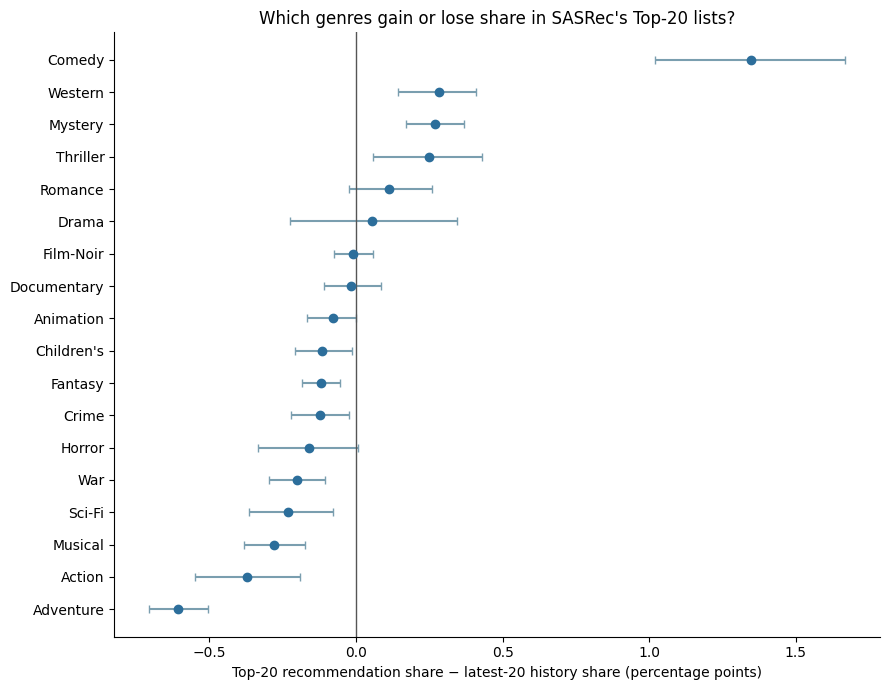

In [8]:
# Genre amplification: mean per-user percentage-point difference with user-bootstrap intervals.
plot_genres = genre_summary.sort_values("delta_mean", ascending=True)
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(plot_genres))
means = 100 * plot_genres.delta_mean.to_numpy()
low = 100 * (plot_genres.delta_mean.to_numpy() - plot_genres.delta_ci_low.to_numpy())
high = 100 * (plot_genres.delta_ci_high.to_numpy() - plot_genres.delta_mean.to_numpy())
ax.errorbar(means, y, xerr=np.vstack([low, high]), fmt="o", color="#2C6E9B", ecolor="#7A9EAF", capsize=3)
ax.axvline(0, color="#555555", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(plot_genres.genre)
ax.set_xlabel("Top-20 recommendation share − latest-20 history share (percentage points)")
ax.set_title("Which genres gain or lose share in SASRec's Top-20 lists?")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "genre_share_change.png", dpi=180, bbox_inches="tight")
plt.show()


Q5 recommendation-minus-history share: 3.6 percentage points (95% user bootstrap CI 3.1 to 4.1)


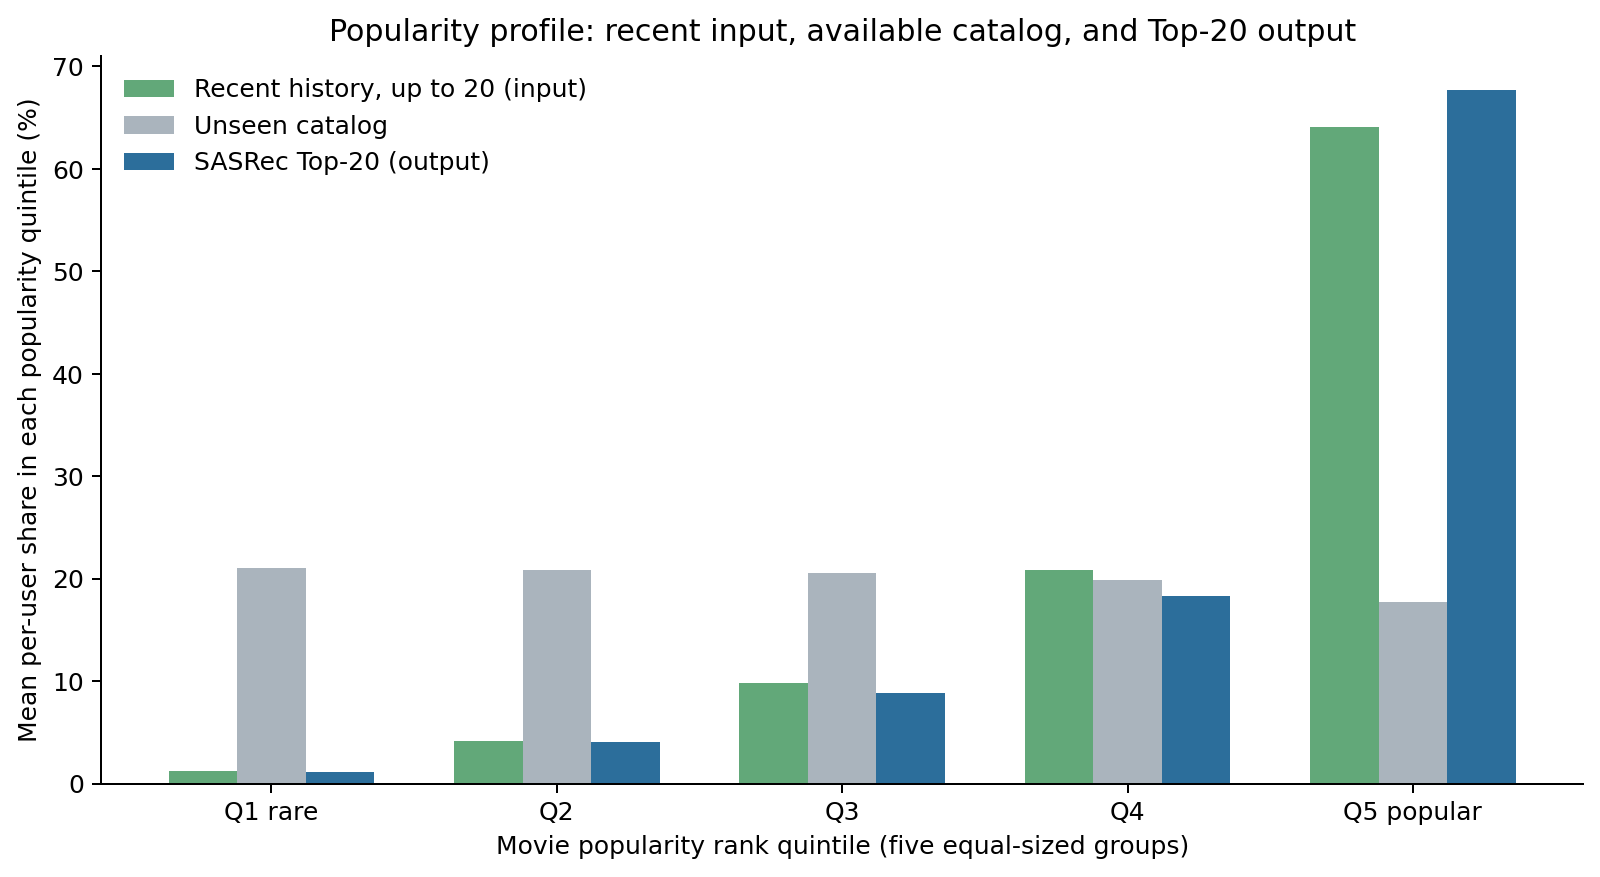

In [9]:
# Popularity exposure: equally sized item-rank quintiles based on training interactions.
pop_summary = popularity_profiles.groupby("popularity_quintile", sort=False).agg(
    latest20_history_share=("latest20_history_share", "mean"),
    unseen_catalog_share=("unseen_catalog_share", "mean"),
    recommendation_exposure_share=("recommendation_exposure_share", "mean"),
    popularity_reference_share=("popularity_reference_share", "mean"),
).reindex(popularity_labels)
pop_summary.to_csv(OUT_DIR / "popularity_history_to_recommendation_summary.csv", index_label="popularity_quintile")
q5_paired = popularity_profiles[popularity_profiles.popularity_quintile == "Q5 popular"].sort_values("user_id")
q5_input_output_delta = (
    q5_paired.recommendation_exposure_share.to_numpy()
    - q5_paired.latest20_history_share.to_numpy()
)
q5_delta_low, q5_delta_high = bootstrap_mean_ci(q5_input_output_delta, seed=8400, draws=5000)
print("Q5 recommendation-minus-history share: %.1f percentage points (95%% user bootstrap CI %.1f to %.1f)" % (
    100 * q5_input_output_delta.mean(), 100 * q5_delta_low, 100 * q5_delta_high
))
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(popularity_labels))
width = 0.24
for offset, (column, label, color) in enumerate([
    ("latest20_history_share", "Recent history, up to 20 (input)", "#62A879"),
    ("unseen_catalog_share", "Unseen catalog", "#AAB4BD"),
    ("recommendation_exposure_share", "SASRec Top-20 (output)", "#2C6E9B"),
]):
    ax.bar(x + (offset - 1) * width, 100 * pop_summary[column].to_numpy(), width,
           label=label, color=color)
ax.set_xticks(x)
ax.set_xticklabels(popularity_labels)
ax.set_xlabel("Movie popularity rank quintile (five equal-sized groups)")
ax.set_ylabel("Mean per-user share in each popularity quintile (%)")
ax.set_title("Popularity profile: recent input, available catalog, and Top-20 output")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "recommendation_popularity_profile.png", dpi=180, bbox_inches="tight")
plt.show()


### User-level input/output view

The grouped bars summarize the average Q1–Q5 profiles. This density plot checks how consistent the Q5 input-to-output change is across individual users. Each hexagon represents users with similar recent-history and recommendation shares; points above the diagonal have a larger Q5 share in the recommendations. The 95% interval is a user bootstrap of the paired mean change.

Mean paired Q5 share change: 3.6 pp (95% user-bootstrap CI 3.1 to 4.1)\n

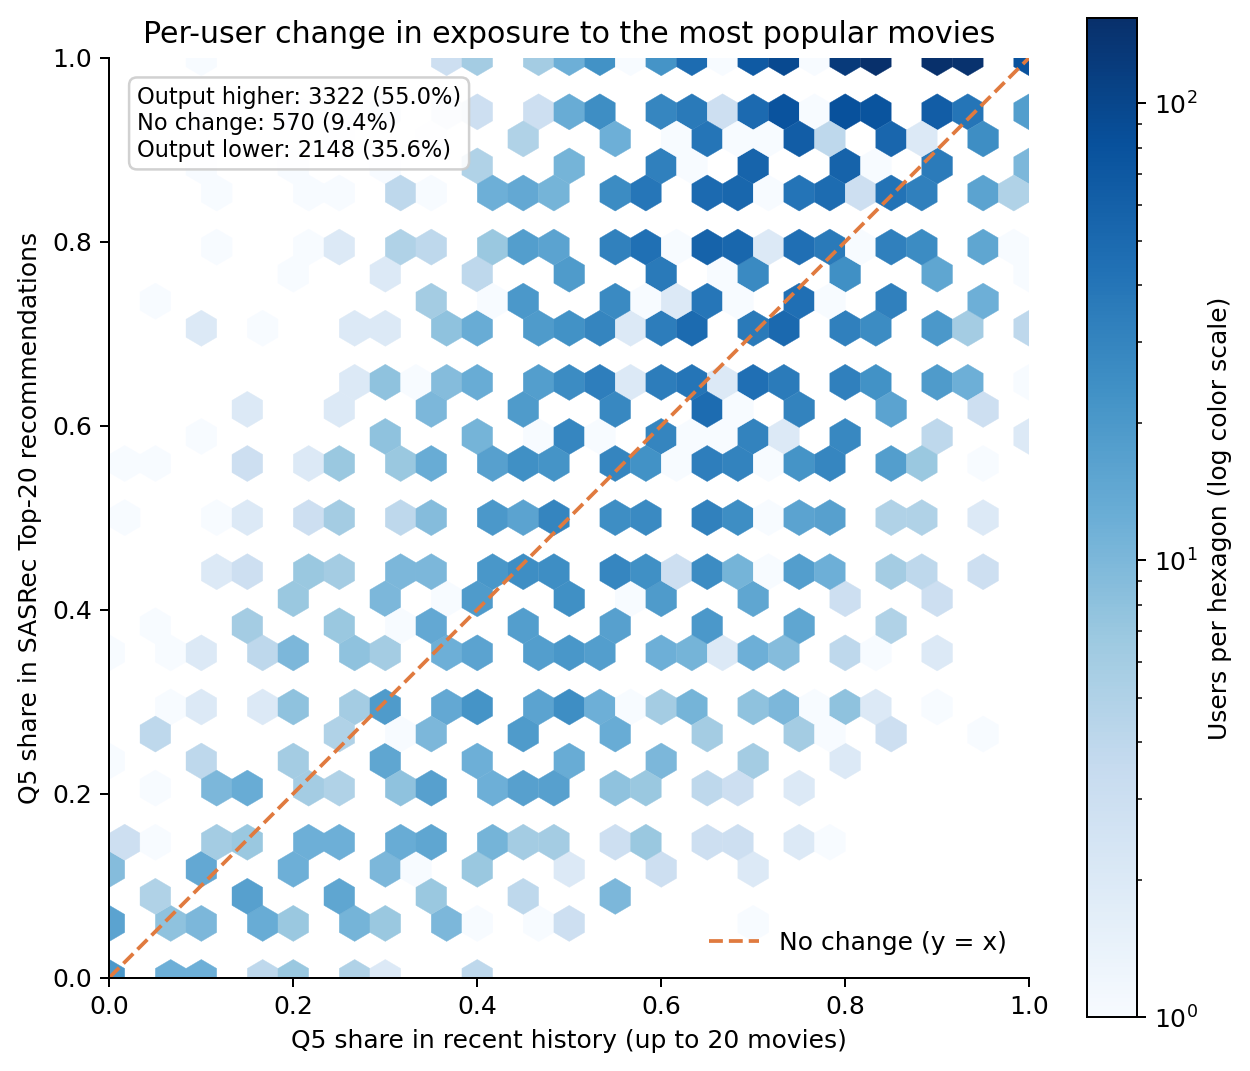

users                                         6040.000000
recommendation_q5_share_higher                3322.000000
recommendation_q5_share_same                   570.000000
recommendation_q5_share_lower                 2148.000000
higher_percent                                  55.000000
same_percent                                     9.437086
lower_percent                                   35.562914
mean_recommendation_minus_history_q5_share       0.036323
mean_shift_ci_low                                0.031352
mean_shift_ci_high                               0.041393
median_history_q5_share                          0.650000
median_recommendation_q5_share                   0.700000

In [11]:
# Per-user paired view: Q5 popularity share in recent history vs Top-20 recommendations.
q5_by_user = popularity_profiles[
    popularity_profiles.popularity_quintile == "Q5 popular"
].sort_values("user_id").copy()
q5_by_user["recommendation_minus_history"] = (
    q5_by_user.recommendation_exposure_share - q5_by_user.latest20_history_share
)
increased = q5_by_user.recommendation_minus_history > 1e-12
decreased = q5_by_user.recommendation_minus_history < -1e-12
unchanged = ~(increased | decreased)
shift_low, shift_high = bootstrap_mean_ci(
    q5_by_user.recommendation_minus_history.to_numpy(), seed=8410, draws=5000
)
q5_user_shift_summary = pd.DataFrame([{
    "users": len(q5_by_user),
    "recommendation_q5_share_higher": int(increased.sum()),
    "recommendation_q5_share_same": int(unchanged.sum()),
    "recommendation_q5_share_lower": int(decreased.sum()),
    "higher_percent": 100 * increased.mean(),
    "same_percent": 100 * unchanged.mean(),
    "lower_percent": 100 * decreased.mean(),
    "mean_recommendation_minus_history_q5_share": q5_by_user.recommendation_minus_history.mean(),
    "mean_shift_ci_low": shift_low,
    "mean_shift_ci_high": shift_high,
    "median_history_q5_share": q5_by_user.latest20_history_share.median(),
    "median_recommendation_q5_share": q5_by_user.recommendation_exposure_share.median(),
}])
q5_user_shift_summary.to_csv(OUT_DIR / "q5_user_level_shift_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7.2, 6.2))
hexes = ax.hexbin(
    q5_by_user.latest20_history_share,
    q5_by_user.recommendation_exposure_share,
    gridsize=30, mincnt=1, bins="log", cmap="Blues", linewidths=0.15,
)
ax.plot([0, 1], [0, 1], color="#E07A3F", linewidth=1.5, linestyle="--", label="No change (y = x)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Q5 share in recent history (up to 20 movies)")
ax.set_ylabel("Q5 share in SASRec Top-20 recommendations")
ax.set_title("Per-user change in exposure to the most popular movies")
cb = fig.colorbar(hexes, ax=ax)
cb.set_label("Users per hexagon (log color scale)")
ax.text(
    0.03, 0.97,
    "Output higher: %d (%.1f%%)\nNo change: %d (%.1f%%)\nOutput lower: %d (%.1f%%)" % (
        increased.sum(), 100 * increased.mean(), unchanged.sum(), 100 * unchanged.mean(),
        decreased.sum(), 100 * decreased.mean()
    ),
    transform=ax.transAxes, va="top", ha="left", fontsize=9,
    bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "alpha": 0.9, "edgecolor": "#CCCCCC"}
)
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "q5_user_input_output_density.png", dpi=180, bbox_inches="tight")
plt.show()
print("Mean paired Q5 share change: %.1f pp (95%% user-bootstrap CI %.1f to %.1f)" % (
    100 * q5_by_user.recommendation_minus_history.mean(), 100 * shift_low, 100 * shift_high
))
display(q5_user_shift_summary)


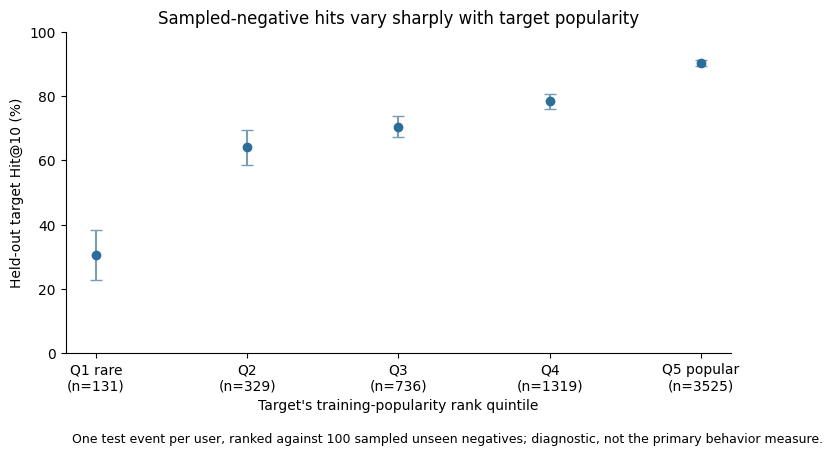

In [11]:
# Test-event hit rate by the held-out movie's training-popularity quintile.
hit_rows = []
for i, label in enumerate(popularity_labels):
    block = test_results[test_results.target_popularity_quintile == label]
    low, high = bootstrap_mean_ci(block.hit_at_10.to_numpy(dtype=float), 7000 + i)
    hit_rows.append({"popularity_quintile": label, "users": len(block), "hit_rate": block.hit_at_10.mean(),
                     "ci_low": low, "ci_high": high})
hit_by_popularity = pd.DataFrame(hit_rows)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(hit_by_popularity))
means = 100 * hit_by_popularity.hit_rate.to_numpy()
low = 100 * (hit_by_popularity.hit_rate.to_numpy() - hit_by_popularity.ci_low.to_numpy())
high = 100 * (hit_by_popularity.ci_high.to_numpy() - hit_by_popularity.hit_rate.to_numpy())
ax.errorbar(x, means, yerr=np.vstack([low, high]), fmt="o", capsize=4,
            color="#2C6E9B", ecolor="#7A9EAF")
ax.set_xticks(x)
ax.set_xticklabels(["%s\n(n=%d)" % (r.popularity_quintile, r.users) for r in hit_by_popularity.itertuples()])
ax.set_ylabel("Held-out target Hit@10 (%)")
ax.set_xlabel("Target's training-popularity rank quintile")
ax.set_title("Sampled-negative hits vary sharply with target popularity")
ax.text(0.01, -0.28, "One test event per user, ranked against 100 sampled unseen negatives; diagnostic, not the primary behavior measure.",
        transform=ax.transAxes, fontsize=9)
ax.set_ylim(0, 100)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "sampled_test_hit_by_target_popularity.png", dpi=180, bbox_inches="tight")
plt.show()


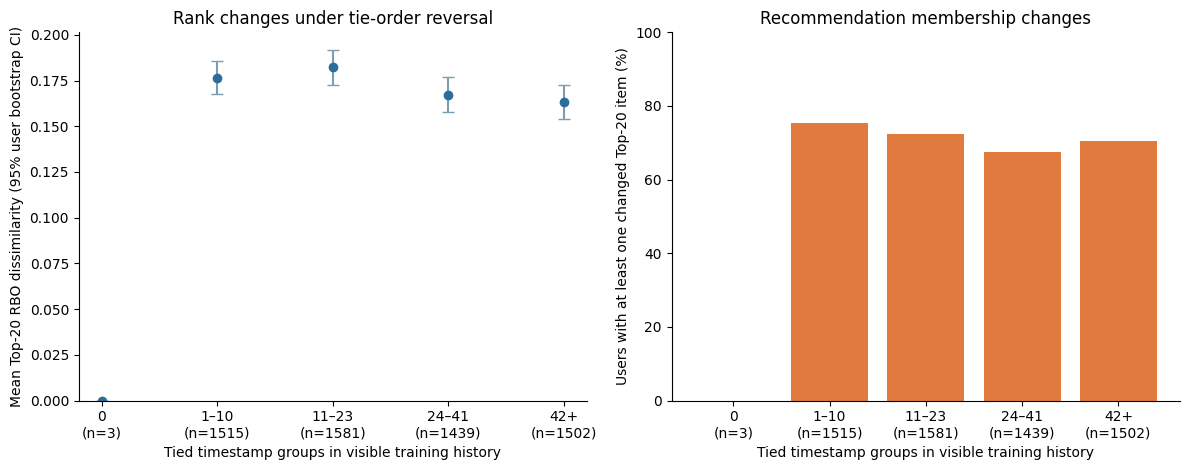

In [12]:
# Same-second order sensitivity: rank and item-set changes across readable tie-count bands.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
summary = sensitivity_summary
x = np.arange(len(summary))
means = summary.mean_rbo_dissimilarity.to_numpy(dtype=float)
low = means - summary.rbo_ci_low.to_numpy(dtype=float)
high = summary.rbo_ci_high.to_numpy(dtype=float) - means
low[~np.isfinite(low)] = 0.0
high[~np.isfinite(high)] = 0.0
axes[0].errorbar(x, means, yerr=np.vstack([low, high]), fmt="o", capsize=4,
                 color="#2C6E9B", ecolor="#7A9EAF")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["%s\n(n=%d)" % (r.tie_group_band, r.users) for r in summary.itertuples()])
axes[0].set_ylabel("Mean Top-20 RBO dissimilarity (95% user bootstrap CI)")
axes[0].set_title("Rank changes under tie-order reversal")
axes[0].set_ylim(bottom=0)
axes[1].bar(x, summary.top20_set_changed_percent, color="#E07A3F")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["%s\n(n=%d)" % (r.tie_group_band, r.users) for r in summary.itertuples()])
axes[1].set_ylabel("Users with at least one changed Top-20 item (%)")
axes[1].set_title("Recommendation membership changes")
axes[1].set_ylim(0, 100)
for ax in axes:
    ax.set_xlabel("Tied timestamp groups in visible training history")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "same_second_order_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()


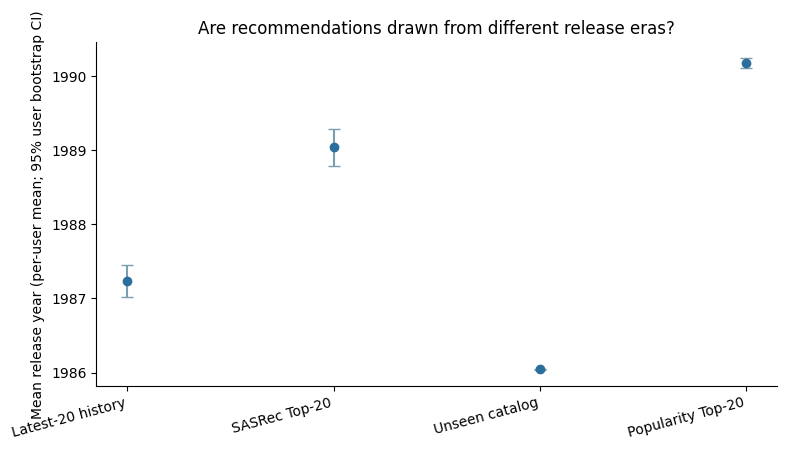

In [13]:
# Secondary descriptive release-year comparison, user-weighted.
release_measures = ["history_mean_year", "recommendation_mean_year", "unseen_catalog_mean_year", "popularity_top20_mean_year"]
release_labels = ["Latest-20 history", "SASRec Top-20", "Unseen catalog", "Popularity Top-20"]
release_means, release_lows, release_highs = [], [], []
for i, measure in enumerate(release_measures):
    values = release_summary_users[measure].to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    lo, hi = bootstrap_mean_ci(values, 5000 + i)
    release_means.append(values.mean())
    release_lows.append(values.mean() - lo)
    release_highs.append(hi - values.mean())
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(release_labels))
ax.errorbar(x, release_means, yerr=np.vstack([release_lows, release_highs]), fmt="o", capsize=4,
            color="#2C6E9B", ecolor="#7A9EAF")
ax.set_xticks(x)
ax.set_xticklabels(release_labels, rotation=15, ha="right")
ax.set_ylabel("Mean release year (per-user mean; 95% user bootstrap CI)")
ax.set_title("Are recommendations drawn from different release eras?")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "release_year_profiles.png", dpi=180, bbox_inches="tight")
plt.show()


In [14]:
# Supplementary descriptive subgroup estimates; not evidence that demographics are model inputs.
demo_summary_rows = []
for (age, gender, genre), group in profiles.groupby(["age", "gender", "genre"], sort=True):
    delta = group.delta_recommendation_minus_history.to_numpy(dtype=float)
    lo, hi = bootstrap_mean_ci(delta, int(age) * 100 + (0 if gender == "F" else 50) + all_genres.index(genre), draws=500)
    demo_summary_rows.append({"age_code": int(age), "gender": gender, "genre": genre, "users": len(group),
                              "delta_mean": delta.mean(), "ci_low": lo, "ci_high": hi})
demographic_summary = pd.DataFrame(demo_summary_rows)
print("Supplementary demographic cells:", len(demographic_summary))
print("Demographics describe subgroup output differences; age/gender are not SASRec input features.")


Supplementary demographic cells: 252
Demographics describe subgroup output differences; age/gender are not SASRec input features.


## 8. Who experiences these patterns? Follow-up comparisons

The overall averages show what changes, but not which users show larger changes. This section compares popularity exposure across users with narrower versus broader genre profiles in their latest 20 interactions. It also checks whether the tie-order stress-test effect differs according to the size of the user's latest model-visible timestamp group. Each user remains one observation. These are descriptive associations; neither grouping establishes a cause.

**What the follow-up shows:** users with broader recent genre profiles receive a larger Q5-popularity exposure gap. The mean gap is 42.4 percentage points for the narrowest third and 55.4 points for the broadest third; the broad-minus-narrow difference is 13.0 points (95% user-bootstrap CI 11.3–14.6). Their unseen-catalog Q5 shares are almost identical (17.7% and 17.8%), so this gap is not explained by a different availability share in these groups. The association is modest across individual users (Spearman ρ = 0.19), so genre breadth alone does not explain recommendation popularity.

The order stress test varies sharply according to whether the latest model-visible timestamp group is tied. When it contains one movie, mean RBO dissimilarity is 0.045 (n=3,480) and 51.2% of users change at least one Top-20 item. For groups of 2, 3, and 4+ movies, mean RBO is 0.346, 0.344, and 0.348; Top-20 membership changes for 99.1%, 99.4%, and 99.1%, respectively. This is a contrast between no tie at the most recent visible time and a tie there, not a dose-response by tie size. Users in the one-movie group still have older tied groups (27.3 on average), all of which were reversed in the stress test. The dataset cannot establish the true within-second order.


In [15]:
# Follow-up: stratify user-level popularity exposure by recent genre diversity.
history_wide = profiles.pivot(index="user_id", columns="genre", values="history_share").fillna(0.0)
history_wide = history_wide.div(history_wide.sum(axis=1).replace(0, np.nan), axis=0)
effective_genres = 1.0 / history_wide.pow(2).sum(axis=1)
q5_user = popularity_profiles[popularity_profiles.popularity_quintile == "Q5 popular"].set_index("user_id")
pop_by_user = user_summary.set_index("user_id").join(
    q5_user[["unseen_catalog_share", "recommendation_exposure_share"]]
).join(effective_genres.rename("effective_history_genres"))
pop_by_user["q5_exposure_gap"] = (
    pop_by_user.recommendation_exposure_share - pop_by_user.unseen_catalog_share
)
pop_by_user["genre_mix_band"] = pd.qcut(
    pop_by_user.effective_history_genres, 3,
    labels=["Narrower genre mix", "Middle", "Broader genre mix"]
)

diversity_rows = []
for index, (band, group) in enumerate(pop_by_user.groupby("genre_mix_band", observed=False)):
    gap_low, gap_high = bootstrap_mean_ci(group.q5_exposure_gap.to_numpy(), 8100 + index)
    diversity_rows.append({
        "genre_mix_band": str(band), "users": len(group),
        "mean_effective_genres": group.effective_history_genres.mean(),
        "mean_q5_recommendation_share": group.recommendation_exposure_share.mean(),
        "mean_q5_unseen_catalog_share": group.unseen_catalog_share.mean(),
        "mean_q5_exposure_gap": group.q5_exposure_gap.mean(),
        "gap_ci_low": gap_low, "gap_ci_high": gap_high,
    })
diversity_summary = pd.DataFrame(diversity_rows)
low = pop_by_user.loc[pop_by_user.genre_mix_band == "Narrower genre mix", "q5_exposure_gap"].to_numpy()
high = pop_by_user.loc[pop_by_user.genre_mix_band == "Broader genre mix", "q5_exposure_gap"].to_numpy()
rng = np.random.RandomState(888)
contrast_draws = np.empty(5000)
for draw in range(len(contrast_draws)):
    contrast_draws[draw] = (
        rng.choice(high, len(high), replace=True).mean()
        - rng.choice(low, len(low), replace=True).mean()
    )
contrast_ci = np.quantile(contrast_draws, [0.025, 0.975])
diversity_summary.to_csv(OUT_DIR / "popularity_by_history_genre_diversity.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(len(diversity_summary))
width = 0.34
ax.bar(x - width / 2, 100 * diversity_summary.mean_q5_unseen_catalog_share, width,
       label="Q5 share of unseen catalog", color="#AAB4BD")
ax.bar(x + width / 2, 100 * diversity_summary.mean_q5_recommendation_share, width,
       label="Q5 share of recommendations", color="#2C6E9B")
ax.set_xticks(x)
ax.set_xticklabels(["%s\n(n=%d)" % (r.genre_mix_band, r.users)
                    for r in diversity_summary.itertuples()])
ax.set_ylabel("Mean Q5 popular-item share (%)")
ax.set_title("Popularity exposure by diversity of recent genre history")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "popularity_by_history_genre_diversity.png", dpi=180, bbox_inches="tight")
plt.show()

# Follow-up: stratify the controlled tie-order stress test by the latest timestamp block.
tie_user = user_summary[["user_id", "visible_latest_timestamp_tie_size", "visible_tie_groups"]].merge(
    sensitivity[["user_id", "rbo_dissimilarity", "top20_set_changed"]], on="user_id", validate="one_to_one"
)
tie_user["latest_tie_band"] = pd.cut(
    tie_user.visible_latest_timestamp_tie_size, [0, 1, 2, 3, np.inf],
    labels=["1 movie (no latest tie)", "2 movies", "3 movies", "4+ movies"]
)
tie_rows = []
for index, (band, group) in enumerate(tie_user.groupby("latest_tie_band", observed=False)):
    rbo_low, rbo_high = bootstrap_mean_ci(group.rbo_dissimilarity.to_numpy(), 8200 + index)
    changed_low, changed_high = bootstrap_mean_ci(group.top20_set_changed.to_numpy(), 8300 + index)
    tie_rows.append({
        "latest_tie_band": str(band), "users": len(group),
        "mean_rbo_dissimilarity": group.rbo_dissimilarity.mean(),
        "rbo_ci_low": rbo_low, "rbo_ci_high": rbo_high,
        "top20_membership_change_rate": group.top20_set_changed.mean(),
        "membership_ci_low": changed_low, "membership_ci_high": changed_high,
        "mean_visible_tie_groups": group.visible_tie_groups.mean(),
    })
tie_size_summary = pd.DataFrame(tie_rows)
tie_size_summary.to_csv(OUT_DIR / "sensitivity_by_latest_tie_size.csv", index=False)
user_summary[["user_id", "visible_latest_timestamp_tie_size", "visible_tie_groups", "train_history_length"]].to_csv(
    OUT_DIR / "visible_latest_timestamp_tie_size.csv", index=False
)

fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(len(tie_size_summary))
means = tie_size_summary.mean_rbo_dissimilarity.to_numpy()
lower = means - tie_size_summary.rbo_ci_low.to_numpy()
upper = tie_size_summary.rbo_ci_high.to_numpy() - means
ax.errorbar(x, means, yerr=np.vstack([lower, upper]), fmt="o-", capsize=4,
            color="#2C6E9B", ecolor="#7A9EAF")
ax.set_xticks(x)
ax.set_xticklabels(["%s\n(n=%d)" % (r.latest_tie_band, r.users)
                    for r in tie_size_summary.itertuples()])
ax.set_ylabel("Mean Top-20 RBO dissimilarity (95% user bootstrap CI)")
ax.set_title("Sensitivity varies with the latest visible timestamp group size")
ax.set_ylim(bottom=0)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "sensitivity_by_latest_tie_size.png", dpi=180, bbox_inches="tight")
plt.show()

print("Broad-minus-narrow Q5 exposure-gap difference: %.1f pp (95%% CI %.1f to %.1f)" % (
    100 * (high.mean() - low.mean()), 100 * contrast_ci[0], 100 * contrast_ci[1]
))
print("Spearman association between recent-history genre diversity and Q5 exposure gap:",
      round(pop_by_user.effective_history_genres.corr(pop_by_user.q5_exposure_gap, method="spearman"), 3))
display(diversity_summary)
display(tie_size_summary)


## 9. Save analysis tables and inspect the most order-sensitive examples

CSV outputs preserve user-level observations for follow-up filtering and comparison. The example table makes the tie-order perturbation inspectable without implying that either order is the true chronology. The follow-up subgroup summaries and figures are also saved in `outputs/`.


In [16]:
# Include item titles in canonical vs perturbed examples with the largest ranking changes.
most_sensitive = sensitivity.sort_values("rbo_dissimilarity", ascending=False).head(12)
example_rows = []
for row in most_sensitive.itertuples():
    user_id = int(row.user_id)
    idx = eligible_users.index(user_id)
    before = canonical_topk[idx].tolist()
    after = reversed_topk[idx].tolist()
    before_rank = {item: rank + 1 for rank, item in enumerate(before)}
    after_rank = {item: rank + 1 for rank, item in enumerate(after)}
    for item in sorted(set(before) | set(after), key=lambda value: min(before_rank.get(value, 999), after_rank.get(value, 999))):
        meta = item_metadata_by_id[item]
        example_rows.append({
            "user_id": user_id, "visible_tie_groups": int(row.visible_tie_groups),
            "rbo_dissimilarity": float(row.rbo_dissimilarity),
            "sas_item_id": item, "title": str(meta["title"]), "genres": str(meta["genres"]),
            "canonical_rank": before_rank.get(item), "tie_reversed_rank": after_rank.get(item),
        })
examples = pd.DataFrame(example_rows)

profiles.to_csv(OUT_DIR / "user_genre_profiles.csv", index=False)
popularity_profiles.to_csv(OUT_DIR / "user_popularity_exposure.csv", index=False)
genre_summary.to_csv(OUT_DIR / "genre_share_summary.csv", index=False)
sensitivity.to_csv(OUT_DIR / "tie_order_sensitivity_users.csv", index=False)
sensitivity_summary.to_csv(OUT_DIR / "tie_order_sensitivity_summary.csv", index=False)
test_results.to_csv(OUT_DIR / "sampled_negative_test_sanity.csv", index=False)
hit_by_popularity.to_csv(OUT_DIR / "sampled_test_hit_by_target_popularity.csv", index=False)
top20_table.to_csv(OUT_DIR / "top20_recommendations.csv", index=False)
user_summary.to_csv(OUT_DIR / "user_summary.csv", index=False)
release_summary_users.to_csv(OUT_DIR / "release_year_user_profiles.csv", index=False)
demographic_summary.to_csv(OUT_DIR / "demographic_genre_summary.csv", index=False)
examples.to_csv(OUT_DIR / "tie_order_sensitive_examples.csv", index=False)

item_exposure = top20_table.groupby("sas_item_id").size().rename("recommendation_slots").reset_index()
item_exposure = item_exposure.merge(item_metadata[["sas_item_id", "original_movie_id", "title", "genres"]],
                                    on="sas_item_id", validate="one_to_one")
item_exposure["slot_share"] = item_exposure.recommendation_slots / float(len(top20_table))
item_exposure = item_exposure.sort_values("recommendation_slots", ascending=False)
item_exposure.to_csv(OUT_DIR / "item_exposure_counts.csv", index=False)
exposure_counts = item_exposure.recommendation_slots.to_numpy()
exposure_counts = np.sort(exposure_counts)[::-1]
recommendation_slots = int(len(top20_table))
exposure_top1pct = int(np.ceil(0.01 * n_items))
exposure_top5pct = int(np.ceil(0.05 * n_items))

results_metadata = {
    "checkpoint_sha256": checkpoint_sha256,
    "repo_commit": "77f86a63af24c83ddd34a5b187a88debaa8ee67f",
    "upstream_model_commit": "26a8fa880f312c3700f8dcca5512d5854b257f4e",
    "interactions": int(len(filtered)), "users": int(n_users), "items": int(n_items),
    "sequence_matches": int(sequence_match_count), "test_users": int(len(test_results)),
    "top_k": TOP_K, "model_maxlen": MAXLEN, "sampled_negative_count": N_NEGATIVES,
    "sampled_negative_hit_at_10": float(test_results.hit_at_10.mean()),
    "sampled_negative_ndcg_at_10": float(np.mean([1.0 / np.log2(row + 1) if row <= 10 else 0.0 for row in test_results.rank_among_101])),
    "users_with_latest_timestamp_tie": int(sum(size > 1 for size in latest_tie_sizes.values())),
    "users_with_visible_training_ties": int(sum(tie_groups_visible[u] > 0 for u in eligible_users)),
    "unique_recommended_items": int(len(exposure_counts)),
    "catalog_coverage": float(len(exposure_counts) / float(n_items)),
    "top_1pct_catalog_exposure_share": float(exposure_counts[:exposure_top1pct].sum() / float(recommendation_slots)),
    "top_5pct_catalog_exposure_share": float(exposure_counts[:exposure_top5pct].sum() / float(recommendation_slots)),
    "most_recommended_item_slot_share": float(exposure_counts[0] / float(recommendation_slots)),
    "tie_sensitivity_order": "reverse events within each equal-timestamp group in the last 200 training events; same item set and candidates",
}
(OUT_DIR / "phase1_run_metadata.json").write_text(json.dumps(results_metadata, indent=2))
print("Recommended unique movies:", len(exposure_counts), "of", n_items,
      "(coverage %.1f%%)" % (100.0 * len(exposure_counts) / n_items))
print("Top 1%% of catalog receives %.1f%% of slots; top 5%% receives %.1f%%." % (
    100.0 * exposure_counts[:exposure_top1pct].sum() / recommendation_slots,
    100.0 * exposure_counts[:exposure_top5pct].sum() / recommendation_slots,
))
print("Saved outputs to", OUT_DIR)
print("Most order-sensitive examples:")
display(examples.head(20))


Recommended unique movies: 2908 of 3416 (coverage 85.1%)
Top 1% of catalog receives 13.7% of slots; top 5% receives 38.9%.
Saved outputs to /Users/tim/Desktop/JKU/Master AI/AIViz/SasRec-Vis-Analysis/research/phase1/ai_pair/outputs
Most order-sensitive examples:


,user_id,visible_tie_groups,rbo_dissimilarity,sas_item_id,title,genres,canonical_rank,tie_reversed_rank
0,5962,9,0.976251,19,"Silence of the Lambs, The (1991)",Drama|Thriller,NaN,1.0
1,5962,9,0.976251,213,True Lies (1994),Action|Adventure|Comedy|Romance,1.0,NaN
2,5962,9,0.976251,647,Twister (1996),Action|Adventure|Romance|Thriller,2.0,NaN
3,5962,9,0.976251,681,Edward Scissorhands (1990),Drama|Romance,17.0,2.0
4,5962,9,0.976251,9,"Shawshank Redemption, The (1994)",Drama,NaN,3.0
5,5962,9,0.976251,124,"Nutty Professor, The (1996)",Comedy|Fantasy|Romance|Sci-Fi,3.0,NaN
6,5962,9,0.976251,39,Star Wars: Episode I - The Phantom Menace (1999),Action|Adventure|Fantasy|Sci-Fi,4.0,NaN
7,5962,9,0.976251,46,Groundhog Day (1993),Comedy|Romance,NaN,4.0
8,5962,9,0.976251,13,Braveheart (1995),Action|Drama|War,14.0,5.0
9,5962,9,0.976251,1176,Legends of the Fall (1994),Drama|Romance|War|Western,5.0,NaN
